<img src = "https://drive.google.com/uc?export=view&id=1FpwoiW7eC_aEKJ53NReEyrW8qAR3RFs0" alt = "Encabezado MLDS" width = "100%">  </img>

# **Entendimiento del Negocio y Carga de Datos**
---

Este notebook es una plantilla que le puede servir como guía para el primer entregable del proyecto aplicado.

## **0. Integrantes del equipo de trabajo**
---

Por favor incluya los nombres completos y número de identificación de los integrantes del equipo de trabajo:

1. **MARINA ANTOLINEZ CABRERO**

## **1. Marco de Proyecto**
---

Normalmente, se suele construir un marco de proyecto para mostrar los resultados del entendimiento del negocio. Para ello, se debe dar respuesta a los siguientes elementos:

### **1.1. Trasfondo del Negocio**
---

- ¿Quién es el cliente o los beneficiarios del proyecto? ¿En qué dominio se encuentran (marketing, medicina, entre otros)?
- ¿Qué problemas del negocio o del dominio estamos tratando de solucionar?

El proyecto se sitúa en el dominio de la robótica asistiva y la ingeniería biomédica.

Mis beneficiarios directos serán los usuarios de prótesis y exoesqueletos (personas con amputaciones o movilidad reducida), que necesitan que sus dispositivos respondan de forma fluida; los equipos clínicos y de rehabilitación, que los emplean en terapia; y los grupos de I+D en biomecatrónica, que diseñan los controladores de estos dispositivos y necesitan saber qué señales, características y modelos son fiables.

Para conseguir que una prótesis o un exoesqueleto se mueva de forma fluida y segura, el sistema debe ser capaz de inferir la intención de movimiento del usuario. Para ello usaré la electromiografía de superficie (EMG), que mide la actividad eléctrica de los músculos mediante electrodos sobre la piel y es una de las fuentes más habituales para este fin, porque refleja la activación muscular que acompaña al movimiento.

Sin embargo, interpretar la señal EMG es difícil, porque:

- Es ruidosa y de baja amplitud.
- Cambia entre personas (anatomía, fuerza, grasa subcutánea) y entre sesiones (colocación de los electrodos, sudor, fatiga).
- Un error de clasificación se traduce en un movimiento no deseado, frustración para el usuario y, en el peor caso, riesgo de daño o caída.

Por todo esto, he definido lo siguiente:

**Objetivo de negocio:** reconocer con fiabilidad qué gesto pretende realizar el usuario, como base para el control de un dispositivo asistivo.

**Meta de machine learning:** construir un modelo de clasificación multiclase supervisada que, a partir de ventanas de señal EMG de 8 canales, prediga el gesto realizado (reposo, puño cerrado, flexión de muñeca, extensión de muñeca, desviación radial y desviación cubital).

**Criterios de éxito:**

- El modelo debe superar con claridad los *baselines* (clasificador de la clase mayoritaria y azar).
- Se evaluará con *accuracy*, *F1 macro* y matriz de confusión, porque las clases pueden estar desbalanceadas.
- Lo más importante, es que busco medir la capacidad de generalizar a sujetos no vistos (validación separando por sujeto), que es la situación real de un dispositivo que se entrega a un usuario nuevo.

### **1.2. Alcance**
---

- ¿Qué  solución se desea implementar?
- ¿Cuáles son los límites y fronteras del proyecto de *machine learning*? ¿Qué aspectos específicos del negocio se incluirán y cuáles se excluyen en el alcance del proyecto?
- ¿De qué forma el cliente o beneficiario utilizará el producto del proyecto?

Mi implementación será un pipeline reproducible en Python que haga la siguiente secuencia:
1. Carga de registros EMG
2. Segmentación de ventanas temporales
3. Extracción de características clásicas del dominio del tiempo (RMS, longitud de onda, cruces por cero)
4. Entrenamiento y comparación con  clasificadores de *machine learning* clásico (KNN, SVM, Bosque aleatorio)
5. Evaluación con validación por sujeto.

| Se incluye | Se excluye |
|---|---|
| Clasificación **offline** de gestos de la mano y la muñeca | Control en **tiempo real** y latencia del sistema |
| Seis gestos: reposo, puño, flexión, extensión, desviación radial y cubital | La clase "palma extendida" (solo la realizan 2 sujetos) y los datos sin marcar |
| Dataset público de 8 canales (brazalete MYO) | Adquisición de datos propios y diseño de hardware |
| Modelos de ML clásico con características diseñadas a mano | *Deep learning* y estimación continua de trayectorias |
| Evaluación por sujeto y métricas por clase | Integración con simulación o con un dispositivo real |


\
La limitación de mi proyecto es que el producto no será un dispositivo final, sino un estudio de viabilidad, mediante un modelo entrenado y un análisis de los resultados.
El cual podría ser usado para decidir que características y modelos son adecuados como punto de partida en un controlador de prótesis o exoesqueleto, y cuánto empeora el rendimiento ante un usuario nuevo.


### **1.3. Plan**
---

Puede agregar una lista de actividades con tiempos estimados, un diagrama de Gantt o integrar alguna herramienta de gestión de proyectos para mostrar la planeación del proyecto como [*Jira*](https://www.atlassian.com/software/jira?&aceid=&adposition=&adgroup=144583570757&campaign=19313283508&creative=641924587890&device=c&keyword=jira%20software%20online&matchtype=p&network=g&placement=&ds_kids=p74602877891&ds_e=GOOGLE&ds_eid=700000001558501&ds_e1=GOOGLE&gad_source=1&gclid=CjwKCAiAqNSsBhAvEiwAn_tmxStBdySS6RxbLNGXE0tWTeJc32ffjQD_1EXZvH6hmQkYZm5bTa3sgBoCX3oQAvD_BwE&gclsrc=aw.ds) o [*Trello*](https://trello.com/?&aceid=&adposition=&adgroup=144675712219&campaign=19250238609&creative=641300630637&device=c&keyword=trello&matchtype=e&network=g&placement=&ds_kids=p74526213668&ds_e=GOOGLE&ds_eid=700000001557344&ds_e1=GOOGLE&gad_source=1&gclid=CjwKCAiAqNSsBhAvEiwAn_tmxWW7Gdzf0Szf-mA-piM2GPM7tk8R0HsgpBALLGHNFq1-2xXMQbxB1RoCs-sQAvD_BwE&gclsrc=aw.ds).

El proyecto debe estar terminado hacia el 7 de noviembre. Lo desarrollo yo sola y a la vez que otras asignaturas, así que reparto el trabajo en unas 20 horas en total y dejo el último día como margen por si algo se alarga.

| Etapa | Actividades | Entregable | Tiempo estimado |
|---|---|---|---|
| **Fase 1 – Entendimiento del negocio y datos** | Definir trasfondo, alcance y objetivo; seleccionar y documentar el dataset; cargar y verificar tipos y calidad básica | Este notebook | 15–18 oct (3 h) |
| **Fase 2 – Exploración (EDA)** | Visualizar señales por canal y gesto; distribución de clases; diferencias entre sujetos | Gráficas y conclusiones | 19–23 oct (4 h) |
| **Fase 3 – Preparación de datos** | Eliminar datos sin marcar; segmentar en ventanas con solape; extraer 3 características sencillas (RMS, longitud de onda, cruces por cero); separar entrenamiento y prueba por sujeto | Conjunto de características listo | 24–28 oct (4 h) |
| **Fase 4 – Modelado** | *Baseline*; entrenar y comparar k-NN, SVM y random forest; validación por sujeto. Ajuste de hiperparámetros solo si hay tiempo | Modelos comparados | 29 oct–2 nov (5 h) |
| **Fase 5 – Evaluación y cierre** | Métricas por clase, matriz de confusión, análisis de errores y limitaciones; redactar conclusiones y limpiar el notebook | Informe final | 3–6 nov (4 h) |
| **Margen y entrega** | Colchón por imprevistos y subida del notebook | Entrega | 7 nov |

\
**Riesgos principales y mitigación**

| Riesgo | Mitigación |
|---|---|
| Desbalance de clases (la clase "sin marcar" supone el 64 % de las muestras) | Excluir los datos sin marcar, usar *F1 macro* y ponderar clases |
| Resultados inflados por mezclar ventanas solapadas del mismo sujeto en entrenamiento y prueba | Separar siempre por sujeto |
| Variabilidad entre sujetos | Evaluar con sujetos no vistos y reportar la dispersión |
| El preprocesado consume más tiempo del previsto | Empezar con 3 características sencillas y ampliar solo si hay tiempo |
| Poco tiempo en alguna semana por parciales o entregas de otras asignaturas | Priorizar lo imprescindible (ventanas, 3 características, *baseline* y al menos dos modelos) y recortar lo opcional |

## **2. Datos**
---

En esta sección debe adjuntar una descripción de los datos y agregar el código que permite su tratamiento.

### **2.1. Origen**
---

- ¿De dónde vienen los datos?
- ¿Se usa alguna herramienta o proceso para la descarga de la información?
- ¿Qué tipo de datos estamos manejando?

Los datos los obtuve del **UCI Machine Learning Repository**, conjunto *EMG Data for Gestures* (ID 481), publicado en 2019 bajo licencia **CC BY 4.0**. Enlace: https://archive.ics.uci.edu/dataset/481/emg+data+for+gestures

Se registraron con un brazalete MYO Thalmic colocado en el antebrazo de 36 sujetos. Cada sujeto realizó 2 series de 6 o 7 gestos estáticos; cada gesto se mantuvo 3 segundos con 3 segundos de pausa entre gestos.

Para la descarga, obtengo el archivo comprimido original del repositorio con `urllib` y lo descomprimo con `zipfile` (el código está en la sección 2.2). Uso el archivo original, y no la librería `ucimlrepo`, porque necesito los registros completos organizados por sujeto y por archivo.

Finalmente, los datos son series temporales multicanal de sensores, con variables numéricas continuas y una etiqueta categórica. Cada archivo tiene 10 columnas:

| Columna | Descripción | Tipo |
|---|---|---|
| `tiempo_ms` | Marca de tiempo en milisegundos | Numérica |
| `canal_1` … `canal_8` | Señal EMG de cada uno de los 8 sensores del brazalete | Numérica continua |
| `clase` | Gesto realizado (0 sin marcar, 1 reposo, 2 puño, 3 flexión de muñeca, 4 extensión de muñeca, 5 desviación radial, 6 desviación cubital, 7 palma extendida) | Categórica codificada como entero |

\
Además, al cargar se añaden dos columnas auxiliares, `sujeto` y `archivo`, necesarias para separar los datos por sujeto más adelante. Al cargar, `clase` aparece como `float64` por un único valor nulo; tras eliminarlo (ver 2.2) se convierte a entero.


### **2.2. Carga o Adquisición de Datos**
---

Agregue el código necesario en _Python_ para obtener o cargar los datos.

In [16]:
import glob
import io
import os
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", 20)

In [17]:
URL_DATASET = "https://archive.ics.uci.edu/static/public/481/emg+data+for+gestures.zip"
CARPETA_DATOS = "emg_gestures"


def buscar_archivos(raiz, extension):
    """Devuelve todos los archivos con la extensión dada dentro de la carpeta
    (recursivo)."""

    return sorted(glob.glob(os.path.join(raiz, "**", f"*.{extension}"),
                            recursive=True))


def descargar_dataset(url=URL_DATASET, destino=CARPETA_DATOS):
    """Descarga y descomprime el dataset. No repite la descarga si ya existe."""

    if buscar_archivos(destino, "txt"):
        print(f"El dataset ya está en '{destino}'.")
        return

    os.makedirs(destino, exist_ok=True)
    peticion = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(peticion) as respuesta:
        contenido = respuesta.read()

    with zipfile.ZipFile(io.BytesIO(contenido)) as zip_externo:
        zip_externo.extractall(destino)

    # Por si el repositorio incluye un zip dentro del zip
    for zip_interno in buscar_archivos(destino, "zip"):
        with zipfile.ZipFile(zip_interno) as z:
            z.extractall(os.path.dirname(zip_interno))

    n_archivos = len([a for a in buscar_archivos(destino, "txt") if "readme" not in a.lower()])
    print(f"Descarga completada: {n_archivos} archivos de registros (sin contar el README).")

descargar_dataset()

El dataset ya está en 'emg_gestures'.


In [18]:
COLUMNAS = ["tiempo_ms"] + [f"canal_{i}" for i in range(1, 9)] + ["clase"]

NOMBRES_GESTOS = {
    0: "sin marcar",
    1: "reposo",
    2: "puño cerrado",
    3: "flexión de muñeca",
    4: "extensión de muñeca",
    5: "desviación radial",
    6: "desviación cubital",
    7: "palma extendida",
}


def cargar_dataset(raiz=CARPETA_DATOS):
    """Lee todos los registros y devuelve un único DataFrame con el sujeto
    y el archivo de origen."""

    archivos = [a for a in buscar_archivos(raiz, "txt") if "readme" not in a.lower()]
    if not archivos:
        raise FileNotFoundError(f"No se encontraron archivos .txt en '{raiz}'.")

    tablas = []
    for ruta in archivos:
        tabla = pd.read_csv(ruta, sep=r"\s+")
        if tabla.shape[1] != len(COLUMNAS):
            print(f"Aviso: se omite {ruta} (tiene {tabla.shape[1]} columnas en lugar de {len(COLUMNAS)}).")
            continue
        tabla.columns = COLUMNAS
        tabla["sujeto"] = os.path.basename(os.path.dirname(ruta))
        tabla["archivo"] = os.path.basename(ruta)
        tablas.append(tabla)

    datos = pd.concat(tablas, ignore_index=True)
    datos["sujeto"] = datos["sujeto"].astype("category")
    return datos


datos = cargar_dataset()
datos.head()

,tiempo_ms,canal_1,canal_2,canal_3,canal_4,canal_5,canal_6,canal_7,canal_8,clase,sujeto,archivo
0,1,0.00001,-0.00002,-0.00001,-0.00003,0.00000,-0.00001,0.00000,-0.00001,0.0,01,1_raw_data_13-12_22.03.16.txt
1,5,0.00001,-0.00002,-0.00001,-0.00003,0.00000,-0.00001,0.00000,-0.00001,0.0,01,1_raw_data_13-12_22.03.16.txt
2,6,-0.00001,0.00001,0.00002,0.00000,0.00001,-0.00002,-0.00001,0.00001,0.0,01,1_raw_data_13-12_22.03.16.txt
3,7,-0.00001,0.00001,0.00002,0.00000,0.00001,-0.00002,-0.00001,0.00001,0.0,01,1_raw_data_13-12_22.03.16.txt
4,8,-0.00001,0.00001,0.00002,0.00000,0.00001,-0.00002,-0.00001,0.00001,0.0,01,1_raw_data_13-12_22.03.16.txt


In [19]:
print(datos[datos.isna().any(axis=1)])   # localizar la fila nula
datos = datos.dropna().reset_index(drop=True)
datos["clase"] = datos["clase"].astype(int)

         tiempo_ms  canal_1  canal_2  canal_3  canal_4  canal_5  canal_6  \
3985214      97144 -0.00002 -0.00003 -0.00003 -0.00002 -0.00002      0.0   

         canal_7  canal_8  clase sujeto                        archivo  
3985214      0.0 -0.00001    NaN     34  1_raw_data_10-51_07.04.16.txt  


#### **Verificación de los datos cargados**

Se comprueban dimensiones, tipos de datos, valores nulos, número de sujetos, frecuencia de muestreo y distribución de clases.

In [20]:
print(f"Dimensiones: {datos.shape[0]:,} filas x {datos.shape[1]} columnas")
print(f"Sujetos: {datos['sujeto'].nunique()} | Archivos: {datos['archivo'].nunique()}")
print(f"Valores nulos en total: {int(datos.isna().sum().sum())}")
print()
datos.dtypes

Dimensiones: 4,237,907 filas x 12 columnas
Sujetos: 36 | Archivos: 72
Valores nulos en total: 0



,0
tiempo_ms,int64
canal_1,float64
canal_2,float64
canal_3,float64
canal_4,float64
canal_5,float64
canal_6,float64
canal_7,float64
canal_8,float64
clase,int64


In [22]:
datos[COLUMNAS].describe().T

,count,mean,std,min,25%,50%,75%,max
tiempo_ms,4237907.0,31136.876026,18680.766436,0.00000,15290.00000,30546.00000,45804.00000,97143.00000
canal_1,4237907.0,-0.000008,0.000163,-0.00128,-0.00003,-0.00001,0.00002,0.00127
canal_2,4237907.0,-0.000009,0.000119,-0.00128,-0.00004,-0.00001,0.00002,0.00127
canal_3,4237907.0,-0.000010,0.000124,-0.00128,-0.00004,-0.00001,0.00003,0.00127
canal_4,4237907.0,-0.000010,0.000226,-0.00128,-0.00006,-0.00001,0.00004,0.00127
canal_5,4237907.0,-0.000016,0.000272,-0.00128,-0.00008,-0.00001,0.00005,0.00127
canal_6,4237907.0,-0.000011,0.000215,-0.00128,-0.00006,-0.00001,0.00003,0.00127
canal_7,4237907.0,-0.000009,0.000153,-0.00128,-0.00004,-0.00001,0.00002,0.00127
canal_8,4237907.0,-0.000010,0.000172,-0.00128,-0.00003,-0.00001,0.00001,0.00127
clase,4237907.0,1.265671,1.989693,0.00000,0.00000,0.00000,2.00000,7.00000


In [23]:
# Frecuencia de muestreo estimada a partir de la marca de tiempo (mediana dentro de cada archivo)
paso_ms = datos.groupby("archivo", observed=True)["tiempo_ms"].apply(lambda t: t.diff().median())
print(f"Paso de tiempo mediano: {paso_ms.median():.2f} ms  ->  frecuencia aproximada: {1000 / paso_ms.median():.0f} Hz")

# Distribución de clases
distribucion = datos["clase"].value_counts().sort_index().rename("muestras").to_frame()
distribucion["gesto"] = distribucion.index.map(NOMBRES_GESTOS)
distribucion["porcentaje"] = (100 * distribucion["muestras"] / distribucion["muestras"].sum()).round(2)
distribucion

Paso de tiempo mediano: 1.00 ms  ->  frecuencia aproximada: 1000 Hz


,muestras,gesto,porcentaje
clase,,,
0,2725157,sin marcar,64.30
1,250055,reposo,5.90
2,243193,puño cerrado,5.74
3,249494,flexión de muñeca,5.89
4,251570,extensión de muñeca,5.94
5,251733,desviación radial,5.94
6,253009,desviación cubital,5.97
7,13696,palma extendida,0.32


In [24]:
# Obtenemos cuantas filas repiten exactamente los valores de la fila anterior
canales = [f"canal_{i}" for i in range(1, 9)]
repetidas = (datos[canales].diff().abs().sum(axis=1) == 0).mean()
print(f"{repetidas:.1%} de las filas repiten los valores de la fila anterior")

89.1% de las filas repiten los valores de la fila anterior


In [25]:
# Obtenemos que sujeto realizó cada gesto
sujetos_por_clase = datos.groupby("clase", observed=True)["sujeto"].nunique().rename("n_sujetos").to_frame()
sujetos_por_clase["gesto"] = sujetos_por_clase.index.map(NOMBRES_GESTOS)
sujetos_por_clase

,n_sujetos,gesto
clase,,
0,36,sin marcar
1,36,reposo
2,36,puño cerrado
3,36,flexión de muñeca
4,36,extensión de muñeca
5,36,desviación radial
6,36,desviación cubital
7,2,palma extendida


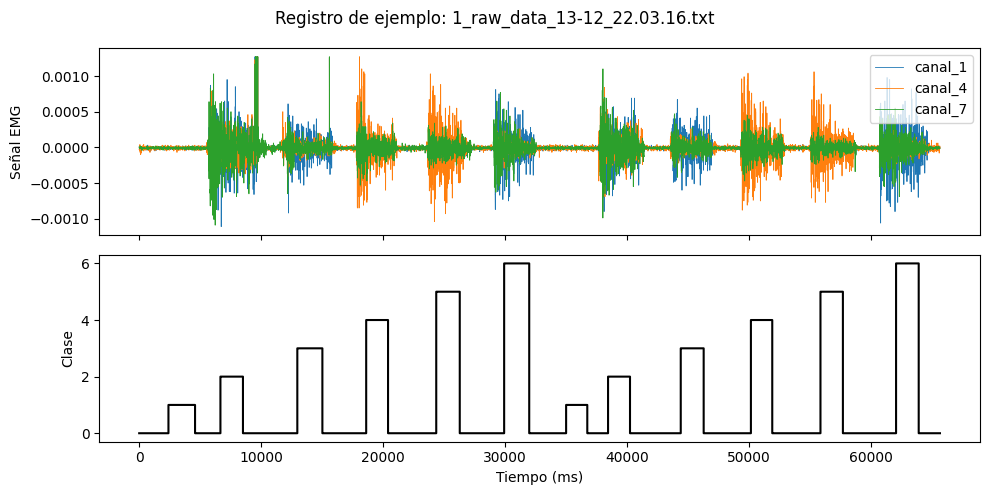

In [26]:
# Vista rápida de un registro: tres canales y la etiqueta del gesto
primer_archivo = datos["archivo"].iloc[0]
muestra = datos[datos["archivo"] == primer_archivo]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
for canal in ["canal_1", "canal_4", "canal_7"]:
    ax1.plot(muestra["tiempo_ms"], muestra[canal], linewidth=0.6, label=canal)
ax1.set_ylabel("Señal EMG")
ax1.legend(loc="upper right")
ax2.step(muestra["tiempo_ms"], muestra["clase"], where="post", color="black")
ax2.set_ylabel("Clase")
ax2.set_xlabel("Tiempo (ms)")
fig.suptitle(f"Registro de ejemplo: {primer_archivo}")
plt.tight_layout()
plt.show()

## **Créditos**
---

* **Profesor:** [Fabio Augusto Gonzalez](https://dis.unal.edu.co/~fgonza/)
* **Asistente docente :**
  * [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Diseño de imágenes:**
    - [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Coordinador de virtualización:**
    - [Edder Hernández Forero](https://www.linkedin.com/in/edder-hernandez-forero-28aa8b207/).

**Universidad Nacional de Colombia** - *Facultad de Ingeniería*